# TP 2 - Predicción de lluvia en Australia

## 1. Análisis descriptivo

El objetivo es estudiar las observaciones meteorológicas y preparar el problema de clasificación de `RainTomorrow`. 

En este primer avance revisamos el archivo entregado, describimos sus variables y hacemos un diagnóstico de los faltantes.

In [1]:
# Importo las librerías que uso en el notebook.
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, balanced_accuracy_score, matthews_corrcoef, average_precision_score, roc_curve, auc

In [2]:
# Cargo el CSV entregado y convierto Date a fecha para resumir el período.
DATA_PATH = Path("weatherAUS_2026C2.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [3]:
# Muestro las primeras filas para ver la estructura del archivo.
display(df.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


### Variables del archivo

El CSV no incluye un diccionario de datos. Esta primera descripción toma los nombres de las columnas y los valores observados en el archivo.

| Variable | Qué representa |
| --- | --- |
| `Unnamed: 0` | Índice que quedó guardado junto con el CSV; no describe el clima. |
| `Date` | Fecha asociada a la observación. |
| `Location` | Ciudad o ubicación de la observación. |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima. |
| `Rainfall` | Lluvia observada en la fecha de la fila. |
| `Evaporation` | Evaporación observada. |
| `Sunshine` | Horas de sol registradas. |
| `WindGustDir`, `WindGustSpeed` | Dirección y velocidad de la ráfaga máxima. |
| `WindDir9am`, `WindDir3pm` | Dirección del viento cerca de las 9 y las 15 h. |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento cerca de las 9 y las 15 h. |
| `Humidity9am`, `Humidity3pm` | Humedad observada cerca de las 9 y las 15 h. |
| `Pressure9am`, `Pressure3pm` | Presión observada cerca de las 9 y las 15 h. |
| `Cloud9am`, `Cloud3pm` | Cobertura de nubes cerca de las 9 y las 15 h. |
| `Temp9am`, `Temp3pm` | Temperatura cerca de las 9 y las 15 h. |
| `RainToday` | Indicador categórico de lluvia en la fecha de la fila. |
| `RainTomorrow` | Indicador de lluvia al día siguiente; es la variable objetivo. |
| `RainfallTomorrow` | Cantidad de lluvia del día siguiente. Se excluye de los predictores porque corresponde a información futura. |



In [4]:
# Resumo tipos, valores distintos y rangos numéricos para completar la descripción.
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores distintos": df.nunique(dropna=True),
    "faltantes": df.isna().sum(),
})
display(estructura)

columnas_numericas = df.select_dtypes(include="number").columns.tolist()
columnas_para_describir = [
    columna for columna in columnas_numericas if columna != "Unnamed: 0"
]
columnas_predictoras_numericas = [
    columna for columna in columnas_para_describir if columna != "RainfallTomorrow"
]
variables_numericas = df[columnas_para_describir]
rangos = variables_numericas.describe().T[["min", "50%", "max"]]
rangos = rangos.rename(columns={"min": "mínimo observado", "50%": "mediana", "max": "máximo observado"})
display(rangos.round(2))

,tipo,valores distintos,faltantes
Unnamed: 0,int64,145412,0
Date,datetime64[ns],3435,0
Location,object,49,0
MinTemp,float64,395,1484
MaxTemp,float64,506,1253
Rainfall,float64,681,3260
Evaporation,float64,358,62754
Sunshine,float64,145,69796
WindGustDir,object,16,10316
WindGustSpeed,float64,120,10253


,mínimo observado,mediana,máximo observado
MinTemp,-9.7,12.0,34.1
MaxTemp,-5.1,22.6,49.1
Rainfall,0.0,0.0,371.0
Evaporation,0.0,4.8,145.0
Sunshine,0.0,8.4,14.5
WindGustSpeed,6.0,38.0,135.0
WindSpeed9am,0.0,13.0,130.0
WindSpeed3pm,0.0,18.0,86.0
Humidity9am,0.0,69.9,100.0
Humidity3pm,0.0,52.0,100.0


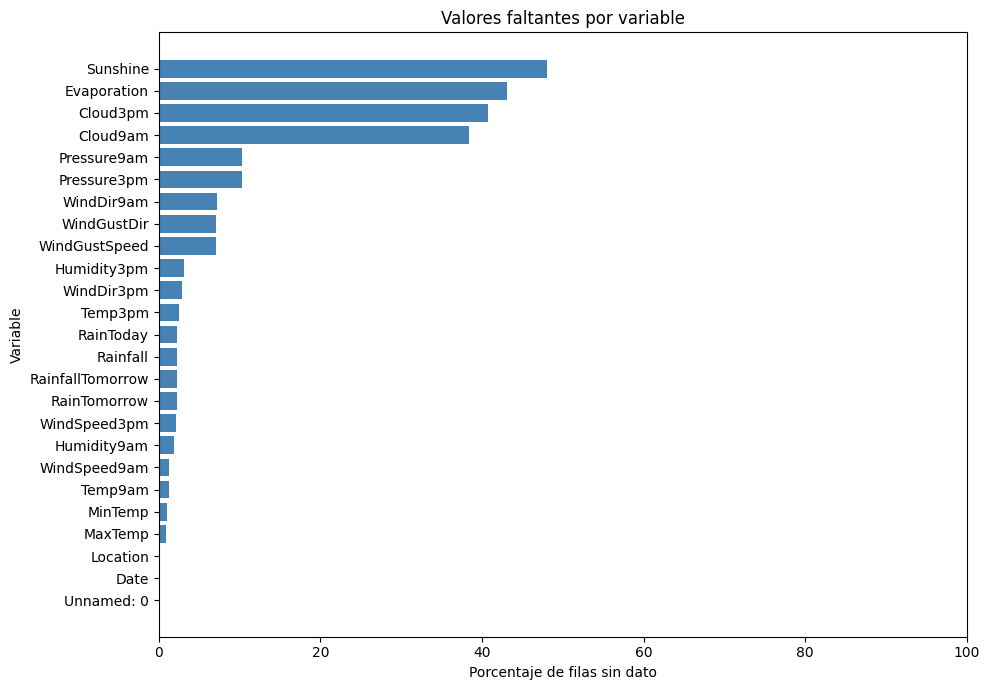

In [5]:
# Calculo y grafico el porcentaje de faltantes para comparar variables en la misma escala.
fig, ax = plt.subplots(figsize=(10, 7))
faltantes = pd.DataFrame({"porcentaje": df.isna().mean() * 100})
faltantes_ordenados = faltantes.sort_values("porcentaje")
ax.barh(faltantes_ordenados.index, faltantes_ordenados["porcentaje"], color="steelblue")
ax.set_title("Valores faltantes por variable")
ax.set_xlabel("Porcentaje de filas sin dato")
ax.set_ylabel("Variable")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### Análisis y decisión sobre los faltantes

Conservamos `Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am` en el conjunto de datos porque describen condiciones meteorológicas que pueden aportar información sobre la lluvia: horas de sol, evaporación y cobertura de nubes en dos momentos del día. No eliminaremos las filas por tener faltante en alguna de estas cuatro columnas. Si lo hiciéramos, perderíamos 82.854 registros (56,98 % del archivo); entre las filas con `RainTomorrow` conocido, solo conservaríamos 62.349 (43,86 %). Además, los faltantes varían por ubicación y año. El tratamiento de estos predictores se definirá más adelante, después de separar entrenamiento y prueba.

Se excluirán del conjunto de modelado las filas que no tengan valor en `RainTomorrow`. Esta columna es la variable objetivo: sin conocer si llovió al día siguiente, no hay una respuesta observada con la cual entrenar el modelo ni comprobar después si acertó. Tampoco corresponde completar esa etiqueta con una moda o una mediana, porque eso asignaría una respuesta no observada y alteraría la distribución de clases.

Esta decisión se aplica a las filas sin etiqueta. Los faltantes en las variables que describen las condiciones del día se analizarán por separado y, si se conservan, se tratarán durante el preprocesamiento. Una mediana o una moda puede servir como estrategia para ciertos predictores, pero no reemplaza el valor faltante de `RainTomorrow`.

### Visualización de datos

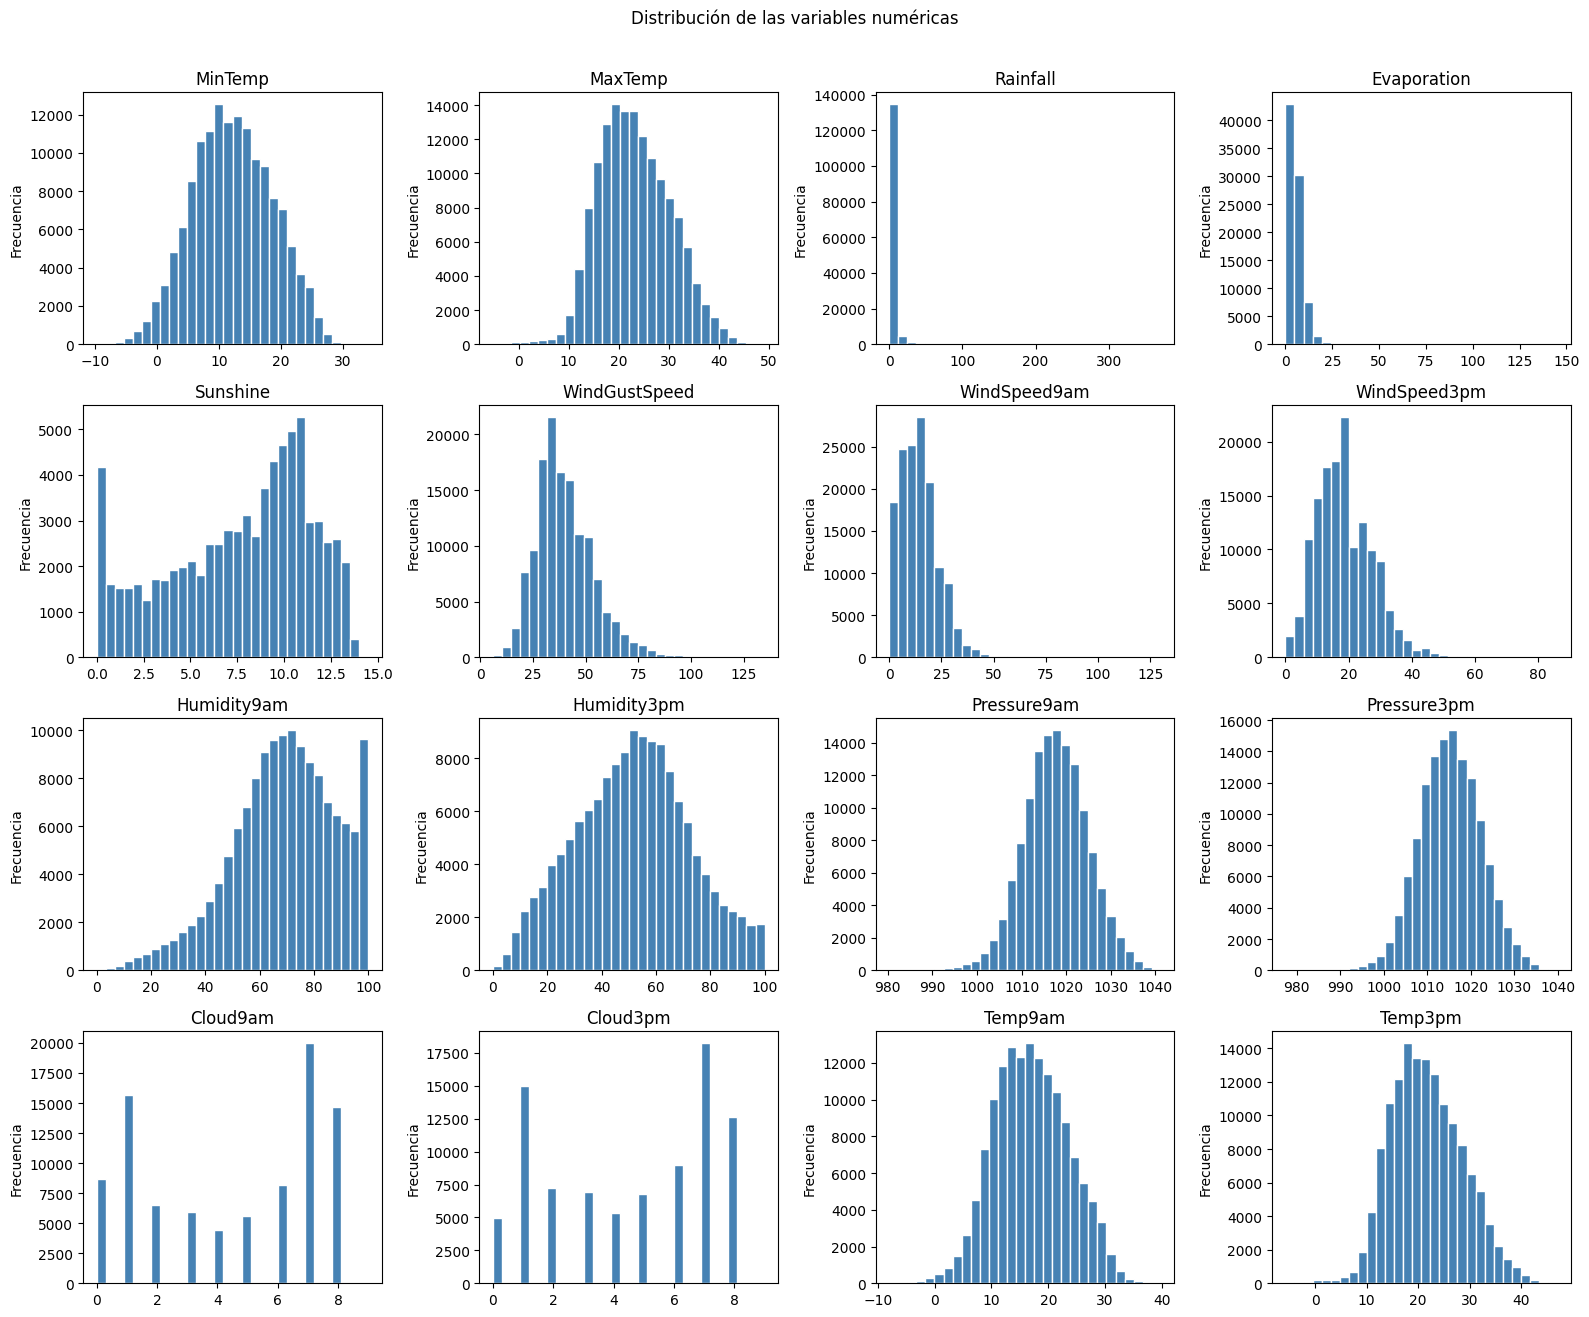

In [6]:
# Grafico las distribuciones de los predictores numéricos definidos en el EDA.
variables_hist = columnas_predictoras_numericas

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, columna in zip(axes.flat, variables_hist):
    datos = df[columna].dropna()
    ax.hist(datos, bins=30, color="steelblue", edgecolor="white")
    ax.set_title(columna)
    ax.set_ylabel("Frecuencia")

for ax in axes.flat[len(variables_hist):]:
    ax.set_visible(False)

fig.suptitle("Distribución de las variables numéricas", y=1.01)
plt.tight_layout()
plt.show()

Para observar asociaciones entre predictores, usamos dos diagramas de dispersión. El color representa la clase observada de RainTomorrow. Se toman hasta 8.000 observaciones completas por gráfico con una semilla fija para mantener la figura legible y reproducible; este muestreo se usa únicamente para graficar.

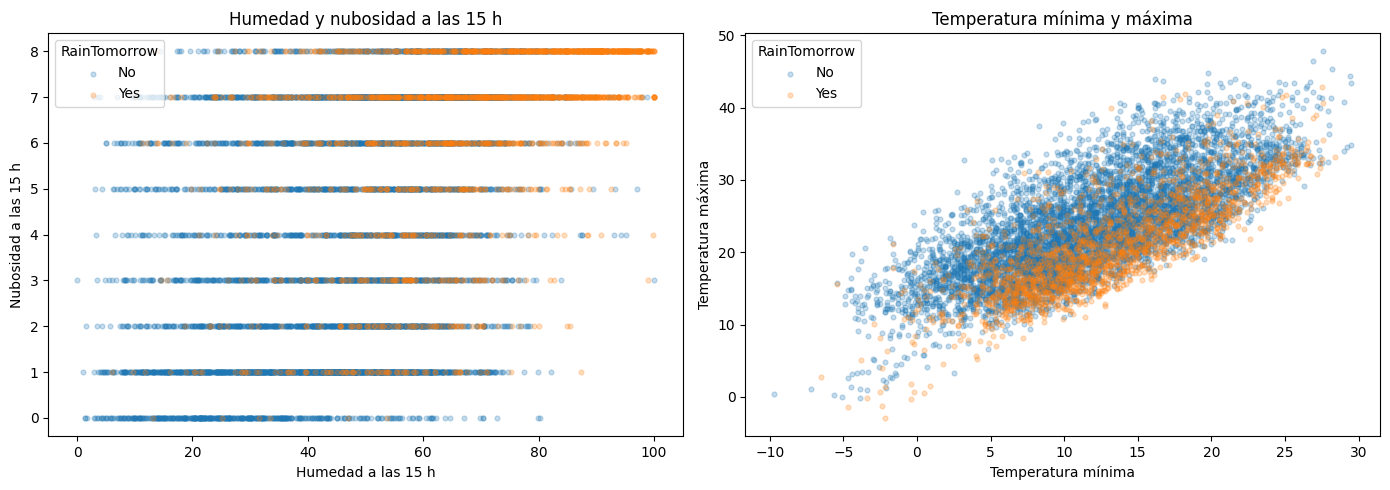

In [7]:
# Comparo humedad con nubosidad y temperatura mínima con máxima, coloreando por la clase objetivo.
colores_clase = {"No": "tab:blue", "Yes": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

datos_humedad_nubes = df.dropna(subset=["Humidity3pm", "Cloud3pm", "RainTomorrow"])
if len(datos_humedad_nubes) > 8000:
    datos_humedad_nubes = datos_humedad_nubes.sample(n=8000, random_state=42)

for clase, color in colores_clase.items():
    grupo = datos_humedad_nubes[datos_humedad_nubes["RainTomorrow"] == clase]
    axes[0].scatter(
        grupo["Humidity3pm"], grupo["Cloud3pm"],
        s=12, alpha=0.25, color=color, label=clase
    )
axes[0].set_title("Humedad y nubosidad a las 15 h")
axes[0].set_xlabel("Humedad a las 15 h")
axes[0].set_ylabel("Nubosidad a las 15 h")
axes[0].legend(title="RainTomorrow", loc="upper left")

datos_temperaturas = df.dropna(subset=["MinTemp", "MaxTemp", "RainTomorrow"])
if len(datos_temperaturas) > 8000:
    datos_temperaturas = datos_temperaturas.sample(n=8000, random_state=42)

for clase, color in colores_clase.items():
    grupo = datos_temperaturas[datos_temperaturas["RainTomorrow"] == clase]
    axes[1].scatter(
        grupo["MinTemp"], grupo["MaxTemp"],
        s=12, alpha=0.25, color=color, label=clase
    )
axes[1].set_title("Temperatura mínima y máxima")
axes[1].set_xlabel("Temperatura mínima")
axes[1].set_ylabel("Temperatura máxima")
axes[1].legend(title="RainTomorrow")

plt.tight_layout()
plt.show()

Los diagramas de caja permiten comparar la mediana y el rango intercuartílico de las cuatro variables con mayor proporción de faltantes, separando las observaciones según RainTomorrow. Se ocultan los puntos extremos para que la zona central sea legible; los valores siguen presentes en el conjunto de datos. Los tamaños de muestra se indican en las etiquetas del eje horizontal.

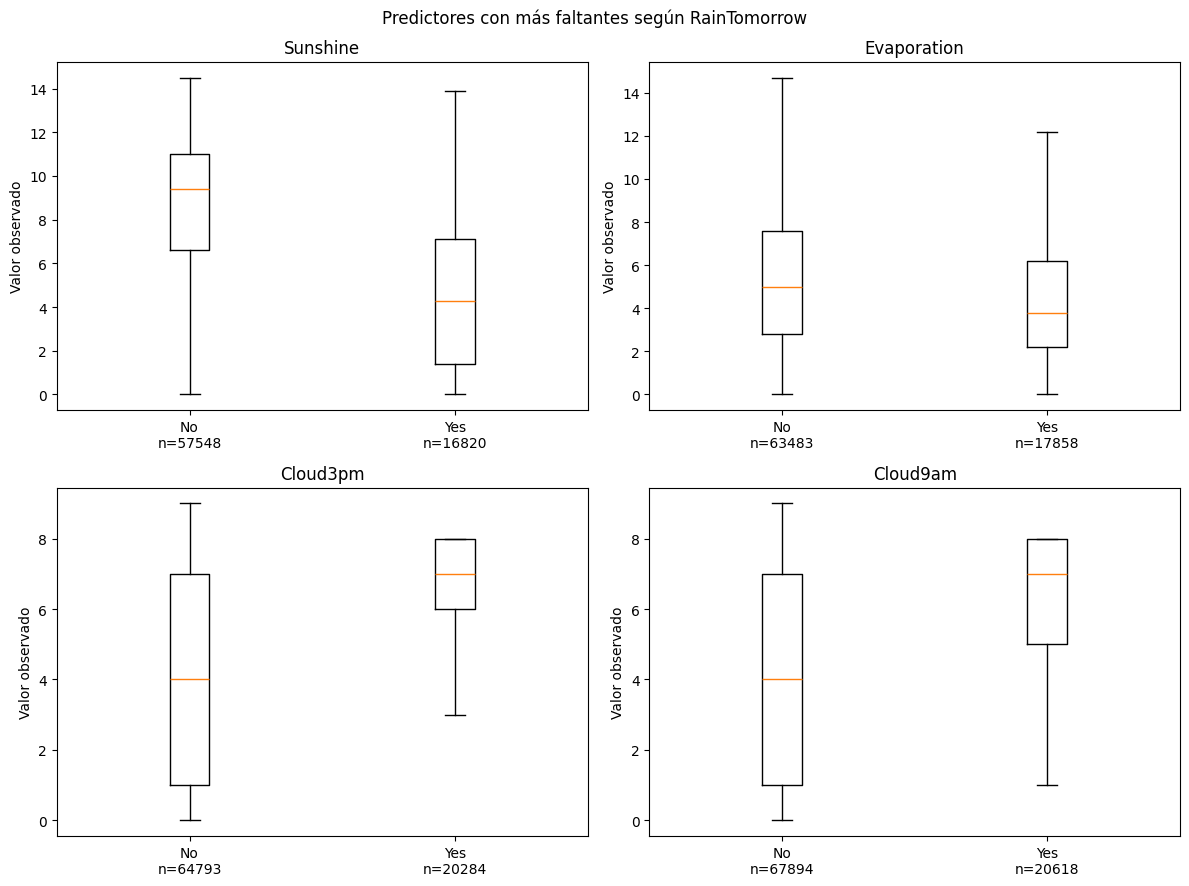

In [8]:
# Comparo por clase las distribuciones de las cuatro variables con mayor proporción de faltantes.
variables_caja = ["Sunshine", "Evaporation", "Cloud3pm", "Cloud9am"]
clases = ["No", "Yes"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, columna in zip(axes.flat, variables_caja):
    valores_por_clase = [
        df.loc[df["RainTomorrow"] == clase, columna].dropna()
        for clase in clases
    ]
    ax.boxplot(valores_por_clase, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"{clase}\nn={len(valores)}"
        for clase, valores in zip(clases, valores_por_clase)
    ])
    ax.set_title(columna)
    ax.set_ylabel("Valor observado")

fig.suptitle("Predictores con más faltantes según RainTomorrow")
plt.tight_layout()
plt.show()

### Lectura de las visualizaciones

Los histogramas muestran que las variables tienen escalas y distribuciones distintas. Por ejemplo, Rainfall concentra muchas observaciones cerca de cero y presenta una cola hacia valores altos; Cloud9am y Cloud3pm toman valores discretos. Esto conviene tenerlo en cuenta al decidir el preprocesamiento.

En los diagramas de caja, la mediana de Sunshine es 9,4 horas para RainTomorrow = No y 4,3 para RainTomorrow = Yes. Para Cloud3pm y Cloud9am, las medianas son 4 y 7, respectivamente; para Evaporation, son 5 y 3,8. En los diagramas de dispersión se observa una relación creciente entre temperatura mínima y máxima, mientras que humedad y nubosidad forman bandas por los valores discretos de nubosidad. Las clases se superponen: estas figuras describen asociaciones del conjunto y no demuestran causalidad ni evalúan el desempeño de un modelo.

Los tamaños de muestra de los diagramas de caja varían porque se omiten los registros sin dato en cada predictor. No se imputaron valores para construir las figuras.

### ¿Está balanceado el dataset?

Para responderlo, observamos la distribución de la variable objetivo RainTomorrow. El cálculo usa únicamente las filas con etiqueta conocida: las observaciones sin RainTomorrow no aportan una clase al conteo y se conservan en df para las decisiones posteriores.

,cantidad,porcentaje
RainTomorrow,,
No,110281,77.58
Yes,31872,22.42


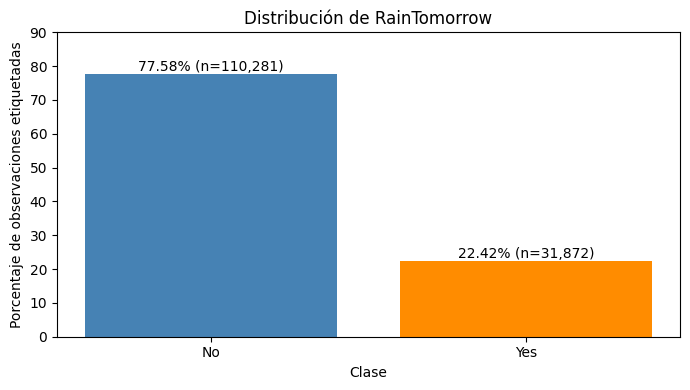

Referencia de mayoría (predecir siempre No): accuracy = 77.58%; recall de Yes = 0.00%.
Filas sin etiqueta excluidas de este conteo: 3,259.


In [9]:
# Cuento las clases conocidas y comparo su proporción con un clasificador constante de referencia.
clases_objetivo = ["No", "Yes"]
conteos_objetivo = (
    df["RainTomorrow"]
    .dropna()
    .value_counts()
    .reindex(clases_objetivo, fill_value=0)
)
total_etiquetado = conteos_objetivo.sum()
balance_objetivo = pd.DataFrame({
    "cantidad": conteos_objetivo,
    "porcentaje": conteos_objetivo / total_etiquetado * 100,
})
balance_objetivo.index.name = "RainTomorrow"
display(balance_objetivo.round({"porcentaje": 2}))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(
    balance_objetivo.index,
    balance_objetivo["porcentaje"],
    color=["steelblue", "darkorange"],
)
for barra, porcentaje, cantidad in zip(
    barras, balance_objetivo["porcentaje"], balance_objetivo["cantidad"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{porcentaje:.2f}% (n={cantidad:,})",
        ha="center",
    )
ax.set_title("Distribución de RainTomorrow")
ax.set_xlabel("Clase")
ax.set_ylabel("Porcentaje de observaciones etiquetadas")
ax.set_ylim(0, 90)
plt.tight_layout()
plt.show()

clase_mayoritaria = conteos_objetivo.idxmax()
accuracy_referencia = conteos_objetivo.max() / total_etiquetado
print(
    f"Referencia de mayoría (predecir siempre {clase_mayoritaria}): "
    f"accuracy = {accuracy_referencia:.2%}; recall de Yes = 0.00%."
)
print(f"Filas sin etiqueta excluidas de este conteo: {df['RainTomorrow'].isna().sum():,}.")

El conjunto no está balanceado respecto de la variable objetivo. Entre las 142.153 filas con etiqueta conocida, 110.281 (77,58 %) corresponden a RainTomorrow = No y 31.872 (22,42 %) a RainTomorrow = Yes; hay aproximadamente 3,46 casos de la clase mayoritaria por cada caso de la minoritaria. Las 3.259 filas sin etiqueta no se incluyen en estas proporciones.

La distribución importa porque un clasificador que siempre predijera No alcanzaría una accuracy de 77,58 %, pero tendría recall de 0 % para los días lluviosos. Por eso, como se trabaja en la unidad de métricas de clasificación, la accuracy por sí sola no alcanza para evaluar el desempeño: luego habrá que revisar métricas por clase y la matriz de confusión.


### Codificación de variables categóricas

Para la predicción usaremos Location, WindGustDir, WindDir9am, WindDir3pm y RainToday como variables categóricas. RainTomorrow es la etiqueta, no un predictor, y Date se usa para ordenar las observaciones y separar entrenamiento y prueba, pero no como predictor.

In [10]:
# Resumo las variables categóricas candidatas y algunos de sus valores observados.
columnas_categoricas = [
    "Location",
    "WindGustDir",
    "WindDir9am",
    "WindDir3pm",
    "RainToday",
]
resumen_categoricas = pd.DataFrame({
    "valores distintos": df[columnas_categoricas].nunique(dropna=True),
    "faltantes": df[columnas_categoricas].isna().sum(),
    "ejemplos": {
        columna: ", ".join(
            df[columna].dropna().astype(str).unique()[:5]
        )
        for columna in columnas_categoricas
    },
})
display(resumen_categoricas)

,valores distintos,faltantes,ejemplos
Location,49,0,"Albury, BadgerysCreek, Cobar, CoffsHarbour, Moree"
WindGustDir,16,10316,"W, WNW, WSW, NE, NNW"
WindDir9am,16,10562,"W, NNW, SE, ENE, SW"
WindDir3pm,16,4226,"WNW, WSW, E, NW, W"
RainToday,2,3260,"No, Yes"


Estas variables son nominales: sus categorías no tienen un orden numérico natural. Por eso usamos pd.get_dummies, que crea una columna de 0 y 1 por categoría, y no asignamos números enteros arbitrarios a direcciones de viento o ubicaciones. Usamos drop_first=True para eliminar una categoría por variable, ya que queda determinada por las demás. Los valores faltantes de estas columnas se conservarán como una categoría propia.

La codificación se hace después de separar entrenamiento y prueba, y las columnas de prueba se alinean con las de entrenamiento.

### Matriz de correlación de variables

Calculamos correlaciones de Pearson entre los predictores numéricos y la etiqueta. Para incluir RainTomorrow en el análisis, usamos una copia temporal con No = 0 y Yes = 1; esta codificación solo se utiliza en la matriz, no modifica df ni reemplaza la codificación prevista para el modelo.

Las filas sin RainTomorrow conocido se excluyen de esta matriz. No imputamos los faltantes: pandas calcula cada correlación con las observaciones disponibles para ese par, por lo que la cantidad de observaciones puede variar entre pares.

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainTomorrow
MinTemp,1.00,0.73,0.10,0.47,0.07,0.18,0.17,0.17,-0.23,0.01,-0.45,-0.46,0.08,0.02,0.90,0.70,0.08
MaxTemp,0.73,1.00,-0.07,0.59,0.47,0.07,0.01,0.05,-0.50,-0.51,-0.33,-0.43,-0.29,-0.28,0.88,0.98,-0.16
Rainfall,0.10,-0.07,1.00,-0.06,-0.23,0.13,0.09,0.06,0.22,0.25,-0.17,-0.13,0.20,0.17,0.01,-0.08,0.24
Evaporation,0.47,0.59,-0.06,1.00,0.37,0.20,0.19,0.13,-0.50,-0.39,-0.27,-0.29,-0.19,-0.18,0.54,0.57,-0.12
Sunshine,0.07,0.47,-0.23,0.37,1.00,-0.03,0.01,0.06,-0.49,-0.63,0.04,-0.02,-0.68,-0.70,0.29,0.49,-0.45
WindGustSpeed,0.18,0.07,0.13,0.20,-0.03,1.00,0.60,0.68,-0.21,-0.03,-0.46,-0.41,0.07,0.11,0.15,0.03,0.23
WindSpeed9am,0.17,0.01,0.09,0.19,0.01,0.60,1.00,0.51,-0.27,-0.03,-0.23,-0.17,0.02,0.05,0.13,0.00,0.09
WindSpeed3pm,0.17,0.05,0.06,0.13,0.06,0.68,0.51,1.00,-0.14,0.02,-0.29,-0.25,0.05,0.03,0.16,0.03,0.09
Humidity9am,-0.23,-0.50,0.22,-0.50,-0.49,-0.21,-0.27,-0.14,1.00,0.66,0.14,0.19,0.45,0.36,-0.47,-0.50,0.26
Humidity3pm,0.01,-0.51,0.25,-0.39,-0.63,-0.03,-0.03,0.02,0.66,1.00,-0.03,0.05,0.52,0.52,-0.22,-0.56,0.44


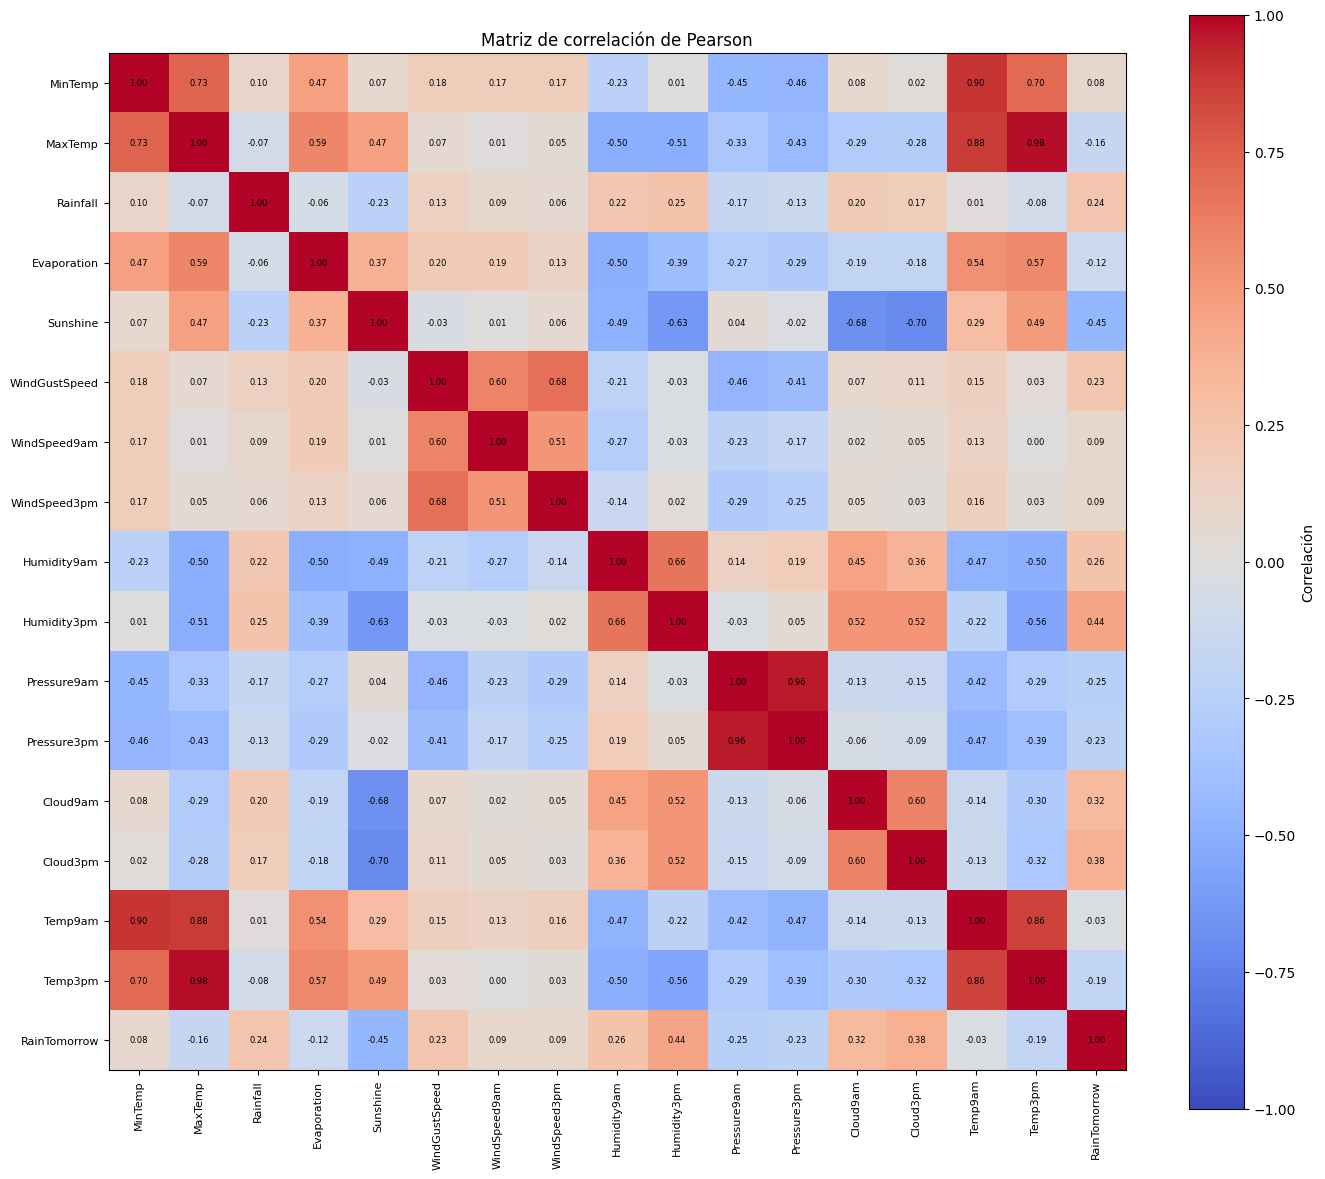

,correlación con RainTomorrow,observaciones válidas
Sunshine,-0.451,74368
Humidity3pm,0.445,138544
Cloud3pm,0.382,85077
Cloud9am,0.317,88512
Humidity9am,0.256,140379
Pressure9am,-0.246,128143
Rainfall,0.239,140747
WindGustSpeed,0.233,132885
Pressure3pm,-0.226,128176
Temp3pm,-0.192,139428


In [11]:
# Calculo y grafico las correlaciones de Pearson sin modificar el conjunto original.
variables_numericas = columnas_predictoras_numericas
datos_correlacion = df.loc[
    df["RainTomorrow"].notna(), variables_numericas
].copy()
datos_correlacion["RainTomorrow"] = (
    df.loc[df["RainTomorrow"].notna(), "RainTomorrow"]
    .map({"No": 0, "Yes": 1})
)

matriz_correlacion = datos_correlacion.corr(method="pearson")
display(matriz_correlacion.round(2))

fig, ax = plt.subplots(figsize=(14, 12))
imagen = ax.imshow(
    matriz_correlacion,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
etiquetas = matriz_correlacion.columns
ax.set_xticks(range(len(etiquetas)))
ax.set_yticks(range(len(etiquetas)))
ax.set_xticklabels(etiquetas, rotation=90, fontsize=8)
ax.set_yticklabels(etiquetas, fontsize=8)
for fila in range(len(etiquetas)):
    for columna in range(len(etiquetas)):
        ax.text(
            columna,
            fila,
            f"{matriz_correlacion.iloc[fila, columna]:.2f}",
            ha="center",
            va="center",
            fontsize=6,
        )
ax.set_title("Matriz de correlación de Pearson")
fig.colorbar(imagen, ax=ax, label="Correlación")
plt.tight_layout()
plt.show()

asociaciones_objetivo = pd.DataFrame({
    "correlación con RainTomorrow": matriz_correlacion["RainTomorrow"].drop("RainTomorrow"),
    "observaciones válidas": datos_correlacion.drop(columns="RainTomorrow").count(),
})
orden = asociaciones_objetivo["correlación con RainTomorrow"].abs().sort_values(
    ascending=False
).index
display(asociaciones_objetivo.loc[orden].round(3))

La matriz muestra asociaciones lineales que pueden orientar la comprensión del conjunto. Las correlaciones más altas con RainTomorrow son Sunshine (−0,451), Humidity3pm (0,445), Cloud3pm (0,382) y Cloud9am (0,317). Entre predictores, MaxTemp y Temp3pm presentan una correlación de 0,98, y Pressure9am y Pressure3pm una de 0,96; son mediciones relacionadas y podrían aportar información parcialmente redundante.

Estas asociaciones no implican causalidad ni bastan, por sí solas, para eliminar variables. La matriz también debe leerse considerando que cada par puede usar una cantidad distinta de filas debido a los faltantes. La correlación de Pearson resume relaciones lineales y puede no describir relaciones más complejas.

### Estandarización/escalado de datos

Los predictores numéricos tienen unidades y rangos distintos, lo que puede afectar a modelos que regularizan sus coeficientes. En el EDA también observamos distribuciones asimétricas y valores extremos. Usaremos `RobustScaler`, que centra con la mediana y escala por el rango intercuartílico; los extremos no determinan esos parámetros y permanecen en los datos transformados.

Como el objetivo es predecir días futuros, reservamos para prueba el tramo cronológico más reciente. Ajustamos el escalador solo con entrenamiento y luego lo aplicamos a prueba. Las variables categóricas quedan sin escalar porque se codificarán por separado. Los faltantes numéricos siguen como `NaN`; el escalado no los imputa.

In [12]:
# Separo cronológicamente las filas etiquetadas y escalo los predictores numéricos con entrenamiento.
datos_etiquetados = df.loc[df["RainTomorrow"].notna()].copy()
columnas_predictoras = columnas_predictoras_numericas + columnas_categoricas
X = datos_etiquetados[columnas_predictoras].copy()
y = datos_etiquetados["RainTomorrow"].copy()

fecha_corte = datos_etiquetados["Date"].quantile(0.80)
mascara_entrenamiento = datos_etiquetados["Date"] <= fecha_corte
X_train = X.loc[mascara_entrenamiento].copy()
X_test = X.loc[~mascara_entrenamiento].copy()
y_train = y.loc[mascara_entrenamiento].copy()
y_test = y.loc[~mascara_entrenamiento].copy()

pipeline_escalado = Pipeline(steps=[("escalador", RobustScaler())])
X_train_escalado = X_train.copy()
X_test_escalado = X_test.copy()
X_train_escalado.loc[:, columnas_predictoras_numericas] = pipeline_escalado.fit_transform(
    X_train[columnas_predictoras_numericas]
)
X_test_escalado.loc[:, columnas_predictoras_numericas] = pipeline_escalado.transform(
    X_test[columnas_predictoras_numericas]
)


resumen_train_escalado = (
    X_train_escalado[columnas_predictoras_numericas]
    .describe()
    .T[["min", "50%", "max"]]
    .round(2)
)
resumen_test_escalado = (
    X_test_escalado[columnas_predictoras_numericas]
    .describe()
    .T[["min", "50%", "max"]]
    .round(2)
)
display(pd.concat({
    "Entrenamiento escalado": resumen_train_escalado,
    "Prueba escalada": resumen_test_escalado,
}, axis=1))

Entrenamiento escalado              Prueba escalada        \
                                 min  50%     max             min   50%   
MinTemp                        -2.34  0.0    2.42           -2.21  0.13   
MaxTemp                        -2.59  0.0    2.65           -2.71  0.16   
Rainfall                        0.00  0.0  463.75            0.00  0.00   
Evaporation                    -1.00  0.0   16.91           -1.00  0.22   
Sunshine                       -1.45  0.0    1.02           -1.45  0.05   
WindGustSpeed                  -1.88  0.0    5.71           -1.88  0.00   
WindSpeed9am                   -1.08  0.0    6.25           -1.08  0.00   
WindSpeed3pm                   -1.50  0.0    5.67           -1.50  0.00   
Humidity9am                    -2.66  0.0    1.15           -2.62  0.01   
Humidity3pm                    -1.80  0.0    1.66           -1.75 -0.00   
Pressure9am                    -3.91  0.0    2.44           -3.78 -0.08   
Pressure3pm                    -3.69  0.0    2.54           -3.96 -0.08   
Cloud9am                       -0.83  0.0    0.67           -0.83  0.17   
Cloud3pm                       -1.00  0.0    0.80           -1.00  0.20   
Temp9am                        -2.50  0.0    2.53           -2.66  0.13   
Temp3pm                        -2.65  0.0    2.68           -2.75  0.13   

                       
                  max  
MinTemp          2.15  
MaxTemp          2.50  
Rainfall       281.25  
Evaporation     30.52  
Sunshine         1.05  
WindGustSpeed    4.94  
WindSpeed9am     9.75  
WindSpeed3pm     3.83  
Humidity9am      1.15  
Humidity3pm      1.66  
Pressure9am      2.35  
Pressure3pm      2.19  
Cloud9am         0.50  
Cloud3pm         0.60  
Temp9am          2.33  
Temp3pm          2.69

### Validación train-test

La tabla permite revisar el período y la proporción de clases en cada conjunto. El tramo de prueba corresponde a fechas posteriores a las usadas para entrenar y queda reservado para la evaluación final. Si más adelante ajustamos hiperparámetros, la validación cruzada se hará dentro de entrenamiento para no usar el conjunto de prueba durante esa selección.

In [13]:
# Compruebo el período y la proporción de clases en cada conjunto.
fechas_train = datos_etiquetados.loc[X_train.index, "Date"]
fechas_test = datos_etiquetados.loc[X_test.index, "Date"]
resumen_validacion = pd.DataFrame({
    "filas": [len(X_train), len(X_test)],
    "fecha inicial": [fechas_train.min().date(), fechas_test.min().date()],
    "fecha final": [fechas_train.max().date(), fechas_test.max().date()],
    "RainTomorrow = No (%)": [
        (y_train == "No").mean() * 100,
        (y_test == "No").mean() * 100,
    ],
    "RainTomorrow = Yes (%)": [
        (y_train == "Yes").mean() * 100,
        (y_test == "Yes").mean() * 100,
    ],
}, index=["Entrenamiento", "Prueba"])
display(resumen_validacion.round({
    "RainTomorrow = No (%)": 2,
    "RainTomorrow = Yes (%)": 2,
}))

,filas,fecha inicial,fecha final,RainTomorrow = No (%),RainTomorrow = Yes (%)
Entrenamiento,113748,2007-11-01,2015-11-09,77.56,22.44
Prueba,28405,2015-11-10,2017-06-24,77.67,22.33


El corte queda en el 9 de noviembre de 2015: entrenamiento reúne 113.748 filas hasta esa fecha y prueba 28.405 filas desde el día siguiente. La proporción de RainTomorrow = Yes es 22,44 % en entrenamiento y 22,33 % en prueba; la de No es 77,56 % y 77,67 %, respectivamente. La partición respeta el orden temporal: entrenamiento incluye las fechas anteriores al corte y prueba, las posteriores. Las proporciones de clases son similares en ambos períodos.

## 2. Regresión logística

### Preprocesamiento

Para la regresión logística necesitamos que todas las columnas sean numéricas y no tengan faltantes. Partimos de los datos escalados con RobustScaler en el ejercicio 1, donde los faltantes numéricos quedaron como NaN.

En las numéricas, imputamos los faltantes con la mediana de entrenamiento. Elegimos la mediana y no la media porque varias variables son asimétricas o tienen valores extremos, como Rainfall y Evaporation. Como RobustScaler centra cada variable en su mediana, la mediana de cada columna escalada en entrenamiento es 0.

En las categóricas, reemplazamos los faltantes por la categoría "Faltante" y aplicamos pd.get_dummies con drop_first=True. Si en prueba falta alguna categoría, reindex agrega esa columna con ceros para que entrenamiento y prueba tengan las mismas columnas y en el mismo orden.

Las medianas se calculan solo con X_train y se aplican a ambos conjuntos.

In [14]:
# Imputo faltantes con valores de entrenamiento y codifico las categóricas con get_dummies.
y_train_bin = (y_train == "Yes").astype(int)
y_test_bin = (y_test == "Yes").astype(int)

medianas_train = X_train_escalado[columnas_predictoras_numericas].median()
X_train_prep = X_train_escalado.copy()
X_test_prep = X_test_escalado.copy()
X_train_prep[columnas_predictoras_numericas] = X_train_prep[columnas_predictoras_numericas].fillna(medianas_train)
X_test_prep[columnas_predictoras_numericas] = X_test_prep[columnas_predictoras_numericas].fillna(medianas_train)

X_train_prep[columnas_categoricas] = X_train_prep[columnas_categoricas].fillna("Faltante")
X_test_prep[columnas_categoricas] = X_test_prep[columnas_categoricas].fillna("Faltante")

X_train_prep = pd.get_dummies(X_train_prep, columns=columnas_categoricas, drop_first=True, dtype=int)
X_test_prep = pd.get_dummies(X_test_prep, columns=columnas_categoricas, drop_first=True, dtype=int)
X_test_prep = X_test_prep.reindex(columns=X_train_prep.columns, fill_value=0)

print("Entrenamiento:", X_train_prep.shape, "Prueba:", X_test_prep.shape)

Entrenamiento: (113748, 114) Prueba: (28405, 114)


In [15]:
# Cuento cuántas columnas dummy generó cada variable categórica.
conteo_dummies = pd.Series({
    columna: X_train_prep.columns.str.startswith(columna + "_").sum()
    for columna in columnas_categoricas
}, name="columnas")
display(conteo_dummies.to_frame())
print("Numéricas:", len(columnas_predictoras_numericas), "| Dummies:", conteo_dummies.sum())

,columnas
Location,48
WindGustDir,16
WindDir9am,16
WindDir3pm,16
RainToday,2


Numéricas: 16 | Dummies: 98


Después del preprocesamiento quedan 114 columnas: las 16 numéricas y 98 dummies. Location aporta 48 (49 ciudades menos la eliminada por drop_first), cada dirección de viento 16 (16 direcciones más "Faltante", menos una) y RainToday 2 (No, Yes y "Faltante", menos una).

### Entrenamiento

Entrenamos dos regresiones logísticas sobre los datos preprocesados. La primera usa los parámetros por defecto. La segunda usa class_weight="balanced", que le asigna más peso en la función de costo a los errores en la clase Yes, en proporción a lo poco frecuente que es. Como el dataset está desbalanceado, queremos ver si esto mejora la detección de días con lluvia.

Subimos max_iter a 1000 porque con el valor por defecto (100) el optimizador no llega a converger.

In [16]:
# Entreno dos regresiones logísticas: una estándar y otra que compensa el desbalance.
modelos = {
    "Logística": LogisticRegression(max_iter=1000),
    "Logística balanceada": LogisticRegression(max_iter=1000, class_weight="balanced"),
}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_prep, y_train_bin)
    print(f"{nombre}: {modelo.n_iter_[0]} iteraciones")

Logística: 290 iteraciones
Logística balanceada: 221 iteraciones


### Métricas

Como el dataset está desbalanceado, no alcanza con la accuracy. Calculamos precision, recall y F1 de la clase Yes, que es la que nos interesa detectar, el recall de la clase No y el AUC, que no depende del umbral.

Además investigamos tres métricas pensadas para clases desbalanceadas, a partir de la documentación de scikit-learn (https://scikit-learn.org/stable/modules/model_evaluation.html):

- Balanced accuracy: promedio del recall de cada clase. Un modelo que predice siempre No obtiene 0,5, mientras que su accuracy sería 0,78.
- Coeficiente de correlación de Matthews (MCC): usa las cuatro celdas de la matriz de confusión, (VP·VN − FP·FN) / √((VP+FP)(VP+FN)(VN+FP)(VN+FN)). Va de −1 a 1, vale 0 para un modelo que no es mejor que predecir una clase constante y solo es alto si el modelo acierta bien en ambas clases.
- Average precision: resume la curva precision-recall en un número. A diferencia del AUC, no usa los verdaderos negativos, así que no se ve favorecida por la gran cantidad de días sin lluvia. Su valor de referencia es la proporción de Yes (0,22).

Medimos todo en entrenamiento y en prueba para después comparar ambos conjuntos y evaluar el fitting.

In [17]:
# Calculo las métricas de cada modelo en entrenamiento y prueba.
conjuntos = {
    "Entrenamiento": (X_train_prep, y_train_bin),
    "Prueba": (X_test_prep, y_test_bin),
}
filas_metricas = []
for nombre, modelo in modelos.items():
    for conjunto, (X_conjunto, y_conjunto) in conjuntos.items():
        y_pred = modelo.predict(X_conjunto)
        y_prob = modelo.predict_proba(X_conjunto)[:, 1]
        filas_metricas.append({
            "modelo": nombre,
            "conjunto": conjunto,
            "accuracy": accuracy_score(y_conjunto, y_pred),
            "precision (Yes)": precision_score(y_conjunto, y_pred),
            "recall (Yes)": recall_score(y_conjunto, y_pred),
            "F1 (Yes)": f1_score(y_conjunto, y_pred),
            "recall (No)": recall_score(y_conjunto, y_pred, pos_label=0),
            "AUC": roc_auc_score(y_conjunto, y_prob),
            "balanced accuracy": balanced_accuracy_score(y_conjunto, y_pred),
            "MCC": matthews_corrcoef(y_conjunto, y_pred),
            "average precision": average_precision_score(y_conjunto, y_prob),
        })

metricas = pd.DataFrame(filas_metricas).set_index(["modelo", "conjunto"])
display(metricas.round(3))

accuracy  precision (Yes)  recall (Yes)  \
modelo               conjunto                                                 
Logística            Entrenamiento     0.850            0.732         0.522   
                     Prueba            0.842            0.721         0.477   
Logística balanceada Entrenamiento     0.797            0.533         0.782   
                     Prueba            0.796            0.530         0.747   

                                    F1 (Yes)  recall (No)    AUC  \
modelo               conjunto                                      
Logística            Entrenamiento     0.609        0.945  0.875   
                     Prueba            0.574        0.947  0.860   
Logística balanceada Entrenamiento     0.634        0.801  0.876   
                     Prueba            0.621        0.810  0.861   

                                    balanced accuracy    MCC  \
modelo               conjunto                                  
Logística            Entrenamiento              0.733  0.531   
                     Prueba                     0.712  0.497   
Logística balanceada Entrenamiento              0.792  0.518   
                     Prueba                     0.779  0.500   

                                    average precision  
modelo               conjunto                          
Logística            Entrenamiento              0.710  
                     Prueba                     0.684  
Logística balanceada Entrenamiento              0.707  
                     Prueba                     0.681

In [18]:
# Muestro precision, recall y F1 de ambas clases para cada modelo en prueba.
for nombre, modelo in modelos.items():
    print(nombre)
    print(classification_report(y_test_bin, modelo.predict(X_test_prep), target_names=["No", "Yes"]))

Logística
              precision    recall  f1-score   support

          No       0.86      0.95      0.90     22061
         Yes       0.72      0.48      0.57      6344

    accuracy                           0.84     28405
   macro avg       0.79      0.71      0.74     28405
weighted avg       0.83      0.84      0.83     28405

Logística balanceada
              precision    recall  f1-score   support

          No       0.92      0.81      0.86     22061
         Yes       0.53      0.75      0.62      6344

    accuracy                           0.80     28405
   macro avg       0.72      0.78      0.74     28405
weighted avg       0.83      0.80      0.81     28405



En prueba, la regresión logística estándar alcanza una accuracy de 0,842, por encima de la referencia de predecir siempre No (77,67 % en prueba). Sin embargo, su recall de Yes es 0,477: detecta menos de la mitad de los días con lluvia. La versión balanceada baja la accuracy a 0,796, pero sube el recall de Yes a 0,747. A cambio, la precision de Yes baja de 0,721 a 0,530, es decir, da más falsas alarmas. El F1 de Yes mejora de 0,574 a 0,621.

El AUC es prácticamente igual en los dos modelos (0,860 y 0,861). Esto indica que ambos ordenan los días según su probabilidad de lluvia casi de la misma forma, y lo que cambia es dónde queda el corte entre Yes y No. Por eso más adelante analizamos el umbral con la curva ROC.

Las métricas adicionales ayudan a separar estos dos efectos. La balanced accuracy favorece al modelo balanceado (0,779 contra 0,712 en prueba), porque premia el aumento del recall de Yes. En cambio, el MCC (0,497 y 0,500) y la average precision (0,684 y 0,681) son prácticamente iguales en ambos modelos y quedan muy por encima de sus valores de referencia (0 y 0,22). Esto confirma lo que muestra el AUC: los dos modelos tienen una capacidad de discriminación similar, y la diferencia está en el umbral de decisión.

### Matrices de confusión

Tomamos Yes como clase positiva. En la matriz, las filas indican el valor real y las columnas la predicción. Un falso positivo es un día en que el modelo predijo lluvia y no llovió (falsa alarma). Un falso negativo es un día en que llovió y el modelo predijo que no (lluvia sin aviso).

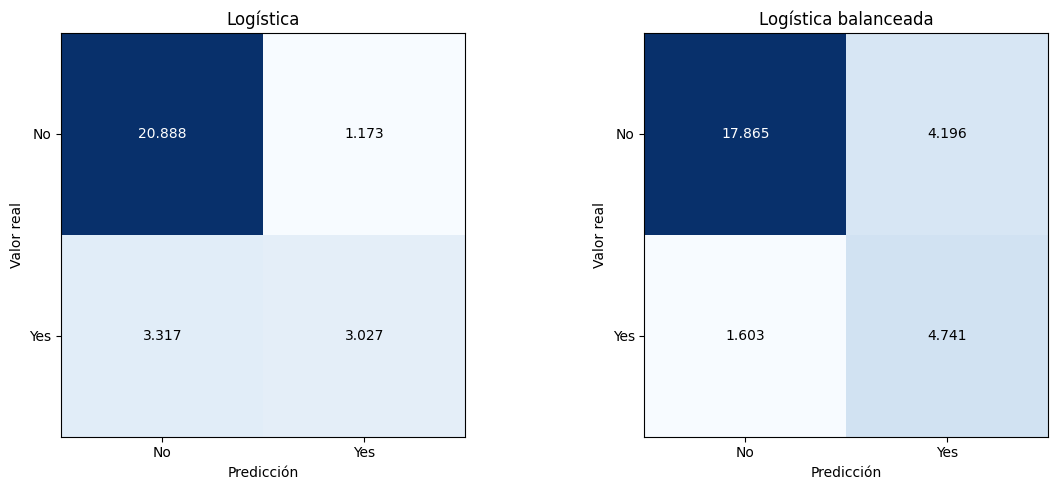

In [19]:
# Defino una función para graficar matrices de confusión y la aplico a cada modelo en prueba.
etiquetas_clases = ["No", "Yes"]

def graficar_matriz_confusion(ax, matriz, titulo):
    ax.imshow(matriz, cmap="Blues")
    for fila in range(2):
        for columna in range(2):
            ax.text(
                columna,
                fila,
                f"{matriz[fila, columna]:,}".replace(",", "."),
                ha="center",
                va="center",
                color="white" if matriz[fila, columna] > matriz.max() / 2 else "black",
            )
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(etiquetas_clases)
    ax.set_yticklabels(etiquetas_clases)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.set_title(titulo)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    matriz = confusion_matrix(y_test_bin, modelo.predict(X_test_prep))
    graficar_matriz_confusion(ax, matriz, nombre)
plt.tight_layout()
plt.show()

La regresión logística estándar tiene 3.317 falsos negativos y 1.173 falsos positivos: se equivoca sobre todo dejando pasar días con lluvia. La versión balanceada reduce los falsos negativos a 1.603, pero sube los falsos positivos a 4.196.

Cuál de los dos errores es más grave depende del uso del pronóstico. Un falso negativo significa que llueve sin aviso, por ejemplo, alguien sale sin paraguas o no protege una cosecha o un evento al aire libre. Un falso positivo es una falsa alarma: se suspende o se prepara algo que no hacía falta. Para un pronóstico de uso general consideramos más costoso el falso negativo, así que priorizamos el recall de Yes sin dejar que la precision caiga demasiado. Esto lo vamos a tener en cuenta al elegir el umbral.

### Curva ROC y elección del umbral

Los modelos predicen Yes cuando la probabilidad estimada es mayor o igual a 0,5, pero ese valor es solo el umbral por defecto. La curva ROC muestra, para todos los umbrales posibles, la tasa de verdaderos positivos (recall de Yes) contra la tasa de falsos positivos.

El umbral es una decisión sobre el modelo, así que no lo elegimos mirando el conjunto de prueba. Separamos el último 20 % de las fechas de entrenamiento como validación, con el mismo criterio cronológico que el split principal, y entrenamos los dos modelos con el resto. Sobre validación calculamos la curva ROC y elegimos el umbral que maximiza la diferencia entre la tasa de verdaderos positivos y la de falsos positivos (índice de Youden). Ese umbral corresponde al punto de la curva más alejado de la diagonal.

In [20]:
# Separo el último tramo de entrenamiento como validación y entreno los modelos sin él.
fecha_corte_validacion = fechas_train.quantile(0.80)
mascara_subentrenamiento = fechas_train <= fecha_corte_validacion
X_subentrenamiento = X_train_prep.loc[mascara_subentrenamiento]
X_validacion = X_train_prep.loc[~mascara_subentrenamiento]
y_subentrenamiento = y_train_bin.loc[mascara_subentrenamiento]
y_validacion = y_train_bin.loc[~mascara_subentrenamiento]

modelos_validacion = {
    "Logística": LogisticRegression(max_iter=1000),
    "Logística balanceada": LogisticRegression(max_iter=1000, class_weight="balanced"),
}
for modelo in modelos_validacion.values():
    modelo.fit(X_subentrenamiento, y_subentrenamiento)

print("Subentrenamiento:", len(X_subentrenamiento), "| Validación:", len(X_validacion), "| Corte:", fecha_corte_validacion.date())

Subentrenamiento: 91027 | Validación: 22721 | Corte: 2014-07-17


Logística: umbral elegido = 0.201 (TPR = 0.758, FPR = 0.195); con 0,5: TPR = 0.462, FPR = 0.045
Logística balanceada: umbral elegido = 0.421 (TPR = 0.785, FPR = 0.220); con 0,5: TPR = 0.725, FPR = 0.168


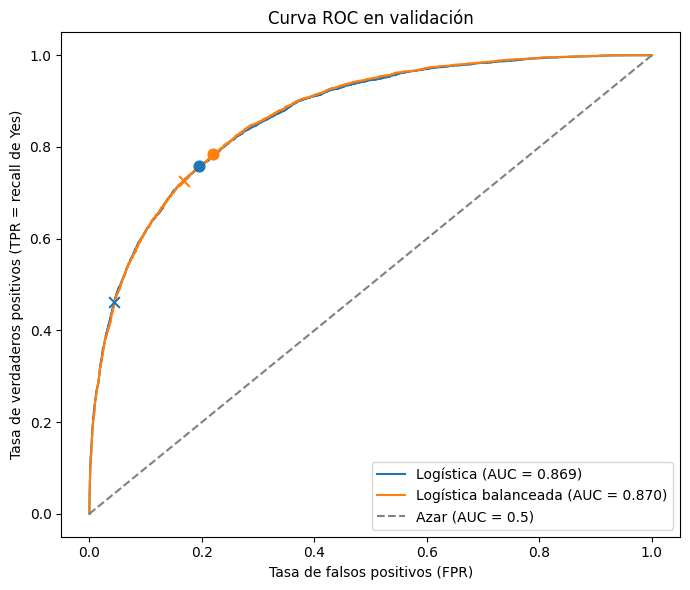

In [21]:
# Grafico la curva ROC de cada modelo en validación y marco el umbral elegido y el de 0,5.
umbrales_elegidos = {}
fig, ax = plt.subplots(figsize=(7, 6))

for nombre, modelo in modelos_validacion.items():
    y_prob_validacion = modelo.predict_proba(X_validacion)[:, 1]
    fpr, tpr, umbrales = roc_curve(y_validacion, y_prob_validacion)
    indice_mejor = (tpr - fpr).argmax()
    umbrales_elegidos[nombre] = umbrales[indice_mejor]

    prediccion_05 = y_prob_validacion >= 0.5
    tpr_05 = (prediccion_05 & (y_validacion == 1)).sum() / (y_validacion == 1).sum()
    fpr_05 = (prediccion_05 & (y_validacion == 0)).sum() / (y_validacion == 0).sum()

    linea, = ax.plot(fpr, tpr, label=f"{nombre} (AUC = {auc(fpr, tpr):.3f})")
    ax.scatter(fpr[indice_mejor], tpr[indice_mejor], color=linea.get_color(), s=60, zorder=3)
    ax.scatter(fpr_05, tpr_05, color=linea.get_color(), marker="x", s=60, zorder=3)
    print(f"{nombre}: umbral elegido = {umbrales[indice_mejor]:.3f} "
          f"(TPR = {tpr[indice_mejor]:.3f}, FPR = {fpr[indice_mejor]:.3f}); "
          f"con 0,5: TPR = {tpr_05:.3f}, FPR = {fpr_05:.3f}")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (TPR = recall de Yes)")
ax.set_title("Curva ROC en validación")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [22]:
# Comparo en prueba el umbral de 0,5 con el umbral elegido en validación.
filas_umbral = []
for nombre, modelo in modelos.items():
    y_prob_prueba = modelo.predict_proba(X_test_prep)[:, 1]
    for umbral in [0.5, umbrales_elegidos[nombre]]:
        y_pred = (y_prob_prueba >= umbral).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_test_bin, y_pred).ravel()
        filas_umbral.append({
            "modelo": nombre,
            "umbral": round(umbral, 3),
            "precision (Yes)": precision_score(y_test_bin, y_pred),
            "recall (Yes)": recall_score(y_test_bin, y_pred),
            "F1 (Yes)": f1_score(y_test_bin, y_pred),
            "balanced accuracy": balanced_accuracy_score(y_test_bin, y_pred),
            "falsos negativos": fn,
            "falsos positivos": fp,
        })

display(pd.DataFrame(filas_umbral).set_index(["modelo", "umbral"]).round(3))

precision (Yes)  recall (Yes)  F1 (Yes)  \
modelo               umbral                                            
Logística            0.500             0.721         0.477     0.574   
                     0.201             0.507         0.773     0.612   
Logística balanceada 0.500             0.530         0.747     0.621   
                     0.421             0.479         0.812     0.602   

                             balanced accuracy  falsos negativos  \
modelo               umbral                                        
Logística            0.500               0.712              3317   
                     0.201               0.778              1442   
Logística balanceada 0.500               0.779              1603   
                     0.421               0.779              1194   

                             falsos positivos  
modelo               umbral                    
Logística            0.500               1173  
                     0.201               4769  
Logística balanceada 0.500               4196  
                     0.421               5610

Las dos curvas ROC casi se superponen (AUC de 0,869 y 0,870 en validación). En el gráfico, la cruz marca el umbral 0,5 y el círculo, el umbral elegido.

¿Es 0,5 el mejor umbral? Para la regresión logística estándar, no. Con 0,5 detecta solo el 46 % de los días con lluvia en validación, mientras que con el umbral elegido (0,201) detecta el 76 %, a cambio de marcar como lluviosos el 19,5 % de los días sin lluvia. En la versión balanceada, el umbral elegido (0,421) queda más cerca de 0,5, porque class_weight ya desplazó las probabilidades hacia la clase Yes.

En prueba, el umbral elegido baja los falsos negativos del modelo estándar de 3.317 a 1.442, y sube los falsos positivos de 1.173 a 4.769. Con su umbral elegido, ambos modelos alcanzan prácticamente la misma balanced accuracy (0,778 y 0,779). Esto confirma que la diferencia principal entre ellos estaba en el punto de corte.

El índice de Youden no es la única forma de elegir el umbral. También se puede elegir el que maximiza el F1, fijar un recall mínimo de Yes y buscar el umbral con mayor precision que lo cumpla, o asignar un costo a cada tipo de error y minimizar el costo total. Elegimos Youden porque no requiere fijar costos arbitrarios y, en un dataset desbalanceado, favorece la detección de la clase minoritaria, que es la que más nos interesa.

### Fitting

Para evaluar el ajuste comparamos las métricas de entrenamiento y prueba. En la regresión logística estándar, la accuracy pasa de 0,850 a 0,842, el F1 de Yes de 0,609 a 0,574 y el AUC de 0,875 a 0,860. En la versión balanceada, la accuracy pasa de 0,797 a 0,796, el F1 de 0,634 a 0,621 y el AUC de 0,876 a 0,861. Las diferencias son chicas, así que no hay señales de sobreajuste: el modelo no memorizó el entrenamiento. Parte de la caída puede deberse a que prueba corresponde a un período posterior.

Tampoco hay un subajuste marcado: ambos modelos superan claramente la referencia de predecir siempre No en las métricas que miden la detección de lluvia, como la balanced accuracy (0,712 y 0,779 contra 0,5) y el MCC (0,497 y 0,500 contra 0). Sin embargo, el desempeño en entrenamiento también es limitado: incluso con los datos que vio, el modelo deja pasar muchos días de lluvia o genera muchas falsas alarmas. Esto es esperable en una regresión logística, cuya frontera de decisión es un hiperplano y no puede capturar relaciones más complejas entre las variables. Consideramos que el fitting es adecuado para este tipo de modelo. En los próximos ítems veremos si un modelo más flexible mejora estos resultados.